In [8]:
import os
from datetime import datetime

TEST_DIR = "test_run"
ONLINE_DIR = "online_rl_trainer/ss_perc_sheet"
BASE_PATH = os.path.join(TEST_DIR, ONLINE_DIR)

def list_online_runs():
    runs = []
    for d in os.listdir(BASE_PATH):
        full = os.path.join(BASE_PATH, d)
        if os.path.isdir(full):
            runs.append((d, os.path.getmtime(full)))

    runs = sorted(runs, key=lambda x: x[1])

    for name, ts in runs:
        print(f"{name}  |  {datetime.fromtimestamp(ts)}")

list_online_runs()


2025_12_04_22_13_58_online_rl_trainer_steps_10_bs_8_lr_1e-05  |  2025-12-04 22:14:01.755841
2026_01_11_13_11_59_online_rl_trainer_steps_10_bs_8_lr_1e-05  |  2026-01-11 13:12:05.391429
2026_01_11_13_12_40_online_rl_trainer_steps_10_bs_8_lr_1e-05  |  2026-01-11 13:12:44.347642
2026_01_11_13_16_44_online_rl_trainer_steps_10_bs_8_lr_1e-05  |  2026-01-11 13:16:49.930023
2026_01_11_13_21_22_online_rl_trainer_steps_200_bs_8_lr_1e-05  |  2026-01-11 13:21:43.645473
2026_01_11_13_41_21_online_rl_trainer_steps_20000_bs_8_lr_5e-06  |  2026-01-11 13:41:24.834233
2026_01_11_13_42_27_online_rl_trainer_steps_20000_bs_8_lr_5e-06  |  2026-01-11 13:42:32.016369
2026_01_11_13_52_07_online_rl_trainer_steps_2000_bs_8_lr_5e-06  |  2026-01-11 13:55:55.133071
2026_01_11_14_03_32_online_rl_trainer_steps_10_bs_8_lr_1e-05  |  2026-01-11 14:03:37.533927
2026_01_11_14_04_16_online_rl_trainer_steps_100_bs_8_lr_1e-05  |  2026-01-11 14:04:30.386725
2026_01_11_14_05_04_online_rl_trainer_steps_2000_bs_8_lr_1e-05  |  202

In [5]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

LOG_FILE = "train_log.csv"
CFG_FILE = "config.json"

def moving_avg(x, w):
    return np.convolve(x, np.ones(w) / w, mode="valid")

def inspect_online_run(run_name, ma_window=200):
    run_path = os.path.join(BASE_PATH, run_name)

    algo = run_name.split("_")[0].upper()  # e.g. A2C / PPO / DPO

    # ---- print basic info ----
    print("\n=== RUN INFO ===")
    print("Run name :", run_name)

    with open(os.path.join(run_path, CFG_FILE)) as f:
        cfg = json.load(f)

    print("Total steps :", cfg["trainer"]["total_optimization_steps"])
    print("Batch size  :", cfg["trainer"]["batch_size"])
    print("LR          :", cfg["optimizer"]["learning_rate"])
    print("KL weight   :", cfg["KL_penalty"]["weight"])
    print("Checkpoint  :", cfg["trainer"]["check_point_freq"])

    # ---- load log ----
    df = pd.read_csv(os.path.join(run_path, LOG_FILE))
    df = df.drop(columns=["Unnamed: 0"], errors="ignore")

    reward = df["reward_mean"].values
    kl = df["KL_mean"].values
    timestep = df.index.values

    print("Timesteps run :", timestep[-1])
    print("Final reward  :", reward[-1])
    print("Final KL      :", kl[-1])

    # ---- moving averages ----
    reward_ma = moving_avg(reward, ma_window)
    kl_ma = moving_avg(kl, ma_window)
    t_ma = timestep[ma_window - 1:]

    x = df["num_samples"].values
    x_ma = x[ma_window - 1:]

    # ---- combined 2x2 plot ----
    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    # Reward vs timestep
    axs[0, 0].plot(t_ma, reward_ma, label=f"{algo} Reward (MA)")
    axs[0, 0].set_xlabel("Timestep")
    axs[0, 0].set_ylabel("Reward mean")
    axs[0, 0].set_title(f"{algo} – Reward vs Timestep")
    axs[0, 0].legend()

    # KL vs timestep
    axs[0, 1].plot(t_ma, kl_ma, label=f"{algo} KL (MA)")
    axs[0, 1].set_xlabel("Timestep")
    axs[0, 1].set_ylabel("KL mean")
    axs[0, 1].set_title(f"{algo} – KL vs Timestep")
    axs[0, 1].legend()

    # Reward vs samples
    axs[1, 0].plot(x_ma, reward_ma, label=f"{algo} Reward (MA)")
    axs[1, 0].set_xlabel("Training samples")
    axs[1, 0].set_ylabel("Reward mean")
    axs[1, 0].set_title(f"{algo} – Reward vs Samples")
    axs[1, 0].legend()

    # KL vs samples
    axs[1, 1].plot(x_ma, kl_ma, label=f"{algo} KL (MA)")
    axs[1, 1].set_xlabel("Training samples")
    axs[1, 1].set_ylabel("KL mean")
    axs[1, 1].set_title(f"{algo} – KL vs Samples")
    axs[1, 1].legend()

    plt.tight_layout()
    plt.show()




=== RUN INFO ===
Run name : 2026_01_12_04_18_59_online_rl_trainer_steps_2000_bs_8_lr_1e-05
Total steps : 2000
Batch size  : 8
LR          : 1e-05
KL weight   : 0.01
Checkpoint  : 2000
Timesteps run : 1999
Final reward  : 3.4557385
Final KL      : 91.2229299545288


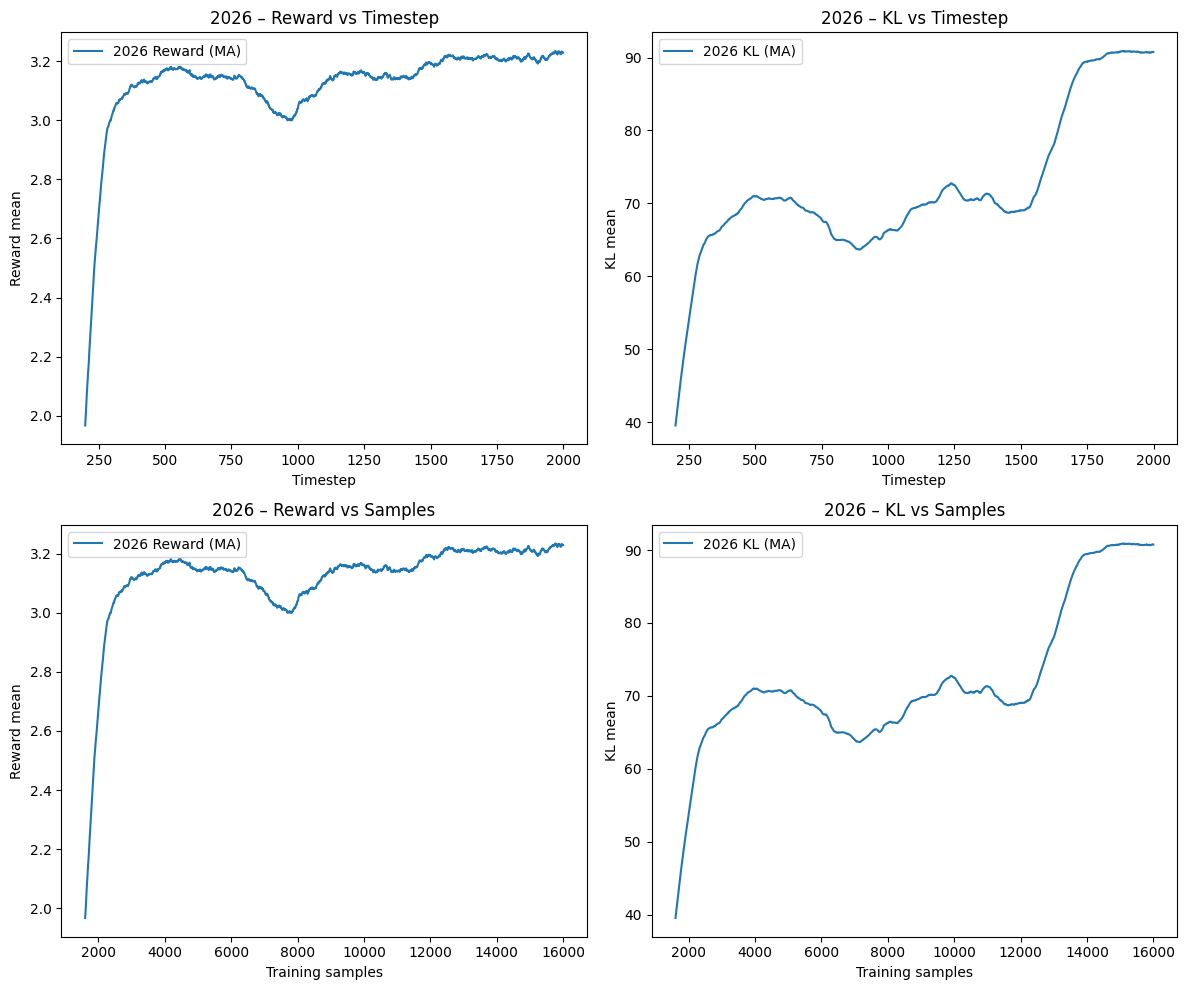

In [9]:
inspect_online_run(
    "2026_01_12_04_18_59_online_rl_trainer_steps_2000_bs_8_lr_1e-05"
)


=== RUN INFO ===
Run name : 2026_01_12_04_31_00_online_rl_trainer_steps_2000_bs_8_lr_5e-06
Total steps : 2000
Batch size  : 8
LR          : 5e-06
KL weight   : 0.01
Checkpoint  : 2000
Timesteps run : 1999
Final reward  : 2.6773896
Final KL      : 49.91755485534668


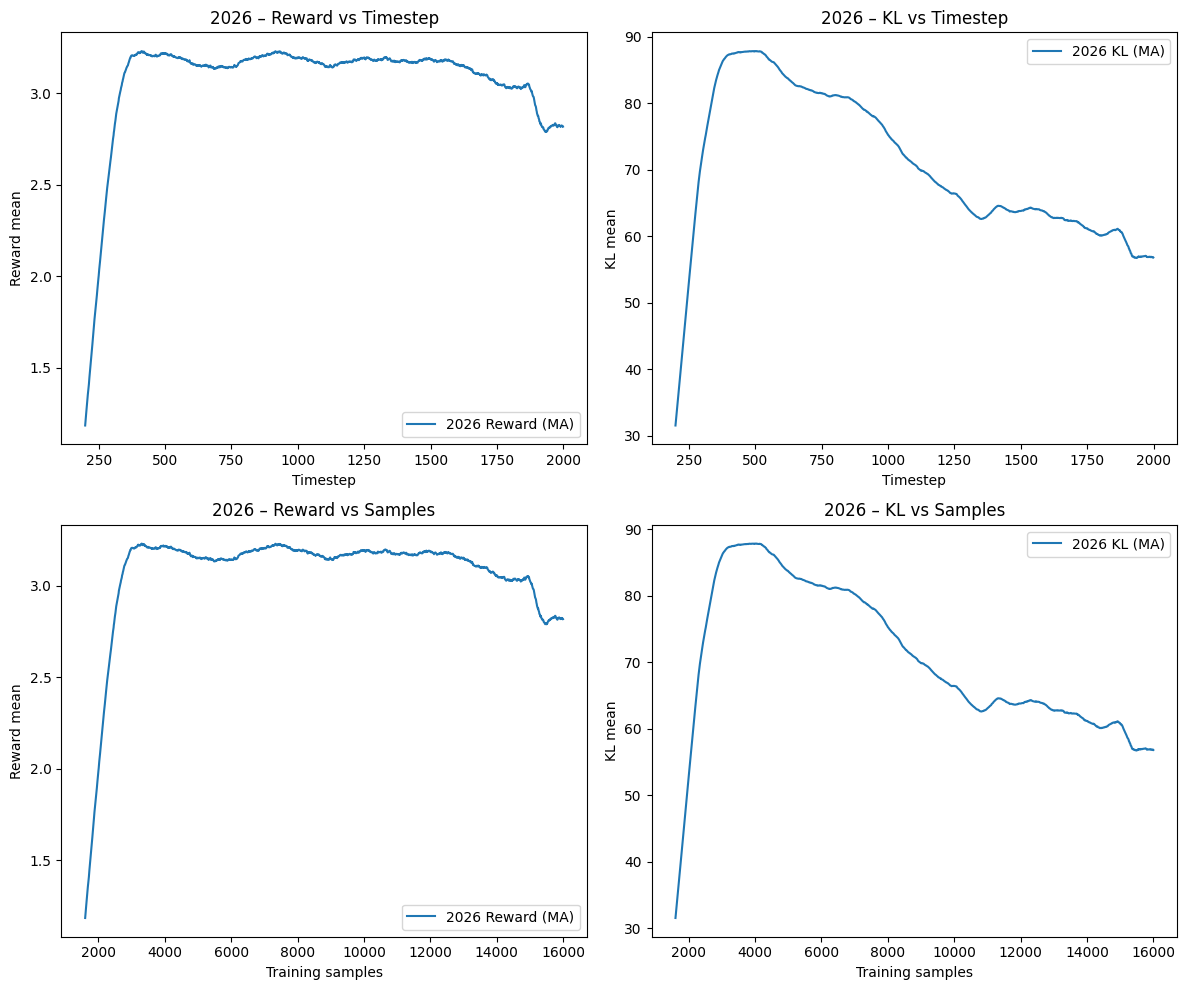

In [10]:
inspect_online_run(
    "2026_01_12_04_31_00_online_rl_trainer_steps_2000_bs_8_lr_5e-06"
)


=== RUN INFO ===
Run name : 2026_01_12_04_36_22_online_rl_trainer_steps_2000_bs_8_lr_1e-05
Total steps : 2000
Batch size  : 8
LR          : 1e-05
KL weight   : 0.01
Checkpoint  : 2000
Timesteps run : 1999
Final reward  : 3.4557385
Final KL      : 84.36414003372192


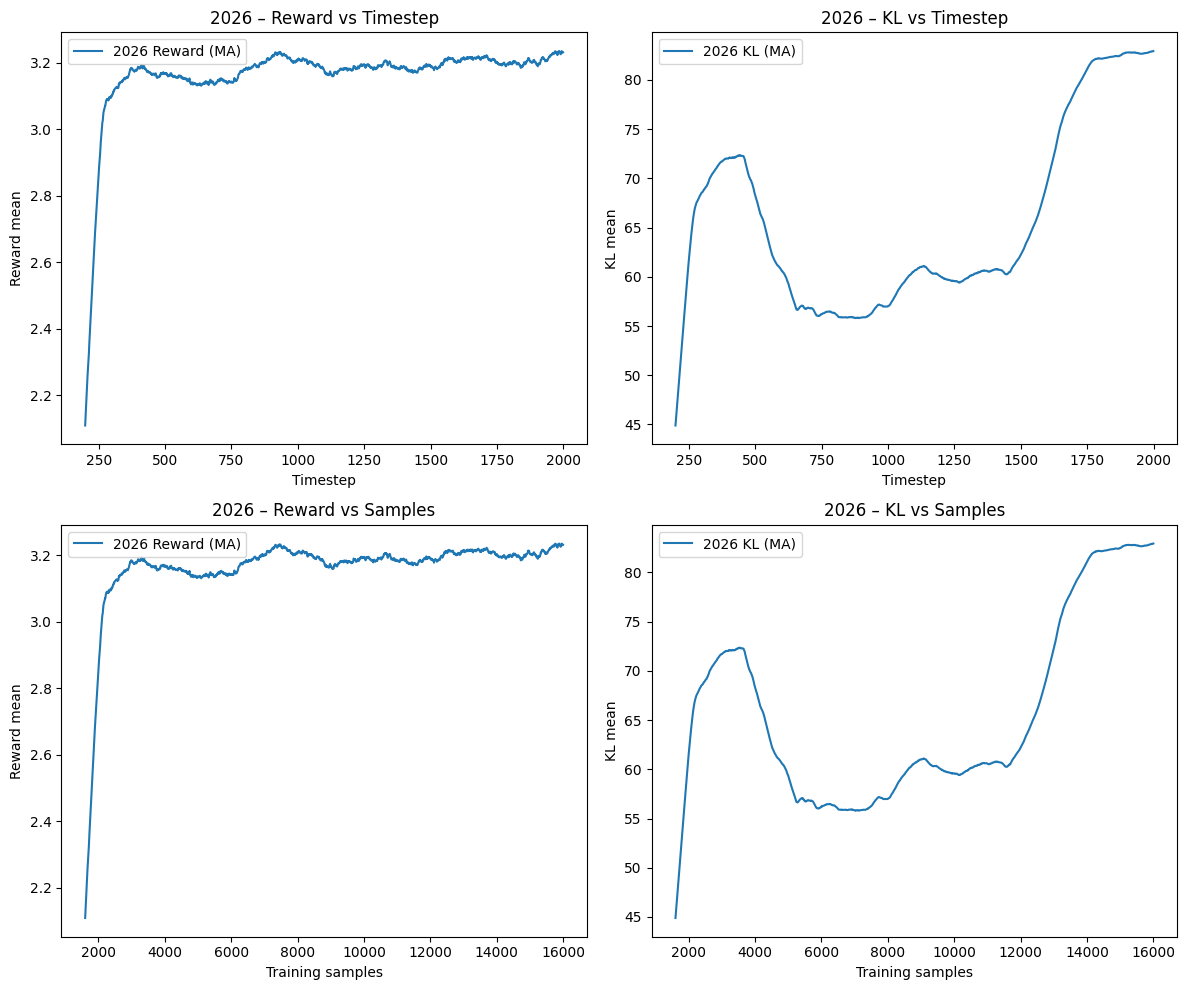

In [11]:
inspect_online_run(
    "2026_01_12_04_36_22_online_rl_trainer_steps_2000_bs_8_lr_1e-05"
)


=== RUN INFO ===
Run name : 2026_01_12_04_52_08_online_rl_trainer_steps_2000_bs_8_lr_1e-05
Total steps : 2000
Batch size  : 8
LR          : 1e-05
KL weight   : 0.02
Checkpoint  : 2000
Timesteps run : 1999
Final reward  : 3.425119
Final KL      : 56.210047006607056


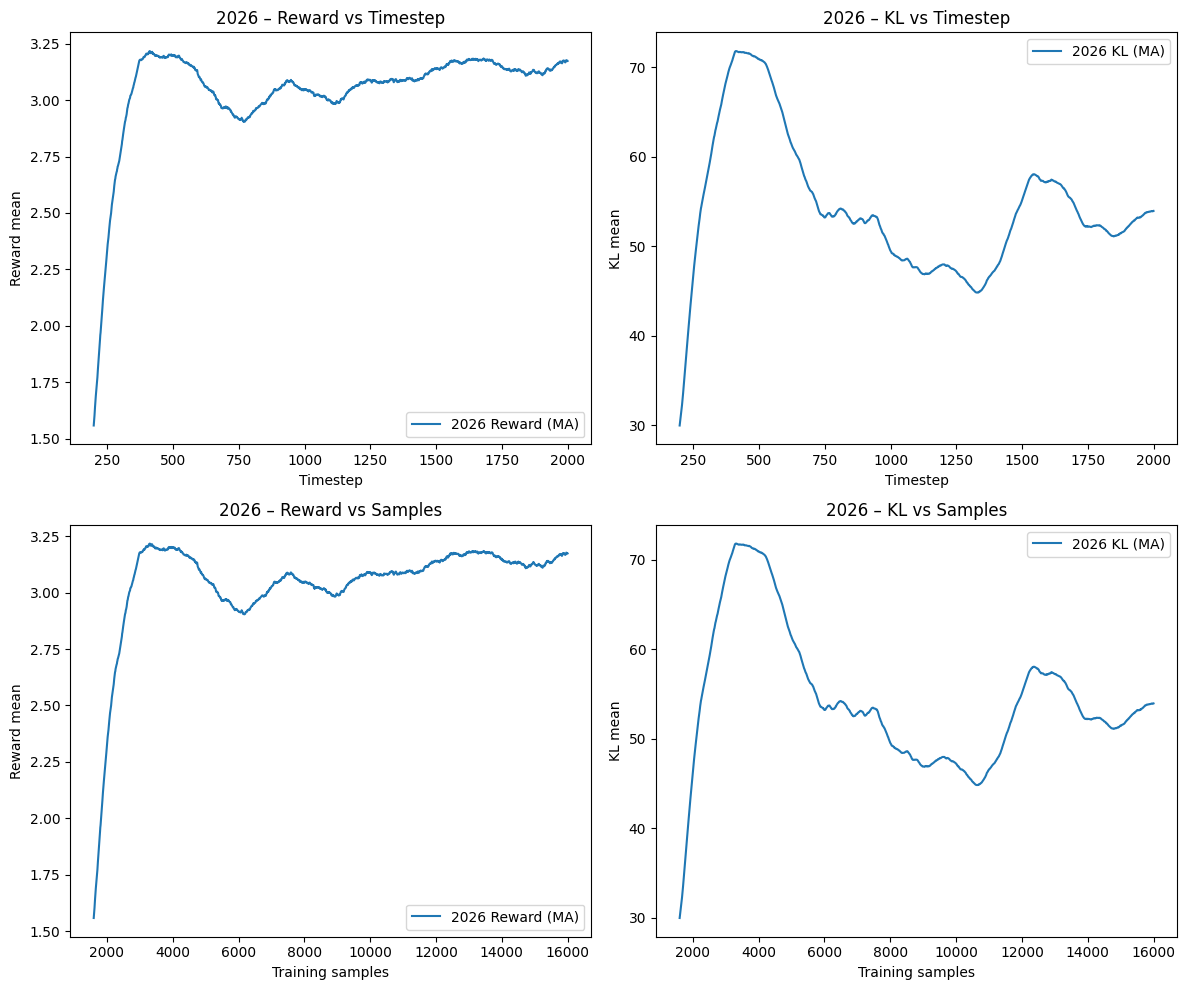

In [12]:
inspect_online_run(
    "2026_01_12_04_52_08_online_rl_trainer_steps_2000_bs_8_lr_1e-05"
)